# Sesión 1 — MUBD

## Manejo básico de Python

Ejecuta cada ejemplo, cambia sus valores y vuelve a ejecutarlo para observar el resultado.
Los ejercicios tienen celdas reservadas para tu solución.

### Trabajar en VS Code

1. Abre la carpeta **LaSalle_Estadistica** y este notebook. Necesitas las extensiones **Python** y **Jupyter**.
2. Selecciona un kernel de Python en la esquina superior derecha.
3. Ejecuta las celdas en orden con **Shift + Enter**. Usa **Ctrl + Enter** para repetir una celda.
4. Abre **Variables** en la barra del notebook para inspeccionar los objetos de la sesión.
   Haz doble clic en una tabla para abrirla en el visor de datos y explorar sus filas y columnas.
5. Usa **Esquema / Outline** para saltar entre apartados. Los controles bajo los gráficos se activan al ejecutar su celda.

Las variables conservan su valor entre ejecuciones. Si cambias una celda, ejecuta también las que dependen de ella.
Puedes usar **Reiniciar** y **Ejecutar todo** para empezar de nuevo.

[Referencia de VS Code: notebooks, variables y visor de datos](https://code.visualstudio.com/docs/datascience/jupyter-notebooks#_variable-explorer-and-data-viewer).

### Preparación

Usaremos NumPy para vectores y matrices, pandas para tablas, Matplotlib para gráficos,
ipywidgets para los controles y statsmodels para el diagrama de mosaico.

Si falta alguna librería en el kernel seleccionado, descomenta y ejecuta la siguiente línea una vez.
Después ejecuta la celda de importaciones.

In [1]:
# %pip install numpy pandas matplotlib ipywidgets statsmodels ipykernel

In [2]:
import calendar
import csv
import math
import string
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from statsmodels.graphics.mosaicplot import mosaic

%matplotlib inline
%config InteractiveShell.ast_node_interactivity = "all"

plt.rcParams.update({"figure.figsize": (8, 4), "figure.dpi": 100})
pd.set_option("display.max_columns", 20)

Las expresiones de una celda muestran sus resultados automáticamente, incluso cuando hay varias.
Una asignación guarda el objeto; escribe su nombre para verlo.

## Cómo pedir ayuda

`help()` muestra la documentación de una función. También puedes escribir `np.mean?`
en una celda o situar el cursor sobre una función en el editor.

In [3]:
help(np.mean)

Help on function mean in module numpy:

mean(a, axis=None, dtype=None, out=None, keepdims=<no value>, *, where=<no value>)
    Compute the arithmetic mean along the specified axis.
    
    Returns the average of the array elements.  The average is taken over
    the flattened array by default, otherwise over the specified axis.
    `float64` intermediate and return values are used for integer inputs.
    
    Parameters
    ----------
    a : array_like
        Array containing numbers whose mean is desired. If `a` is not an
        array, a conversion is attempted.
    axis : None or int or tuple of ints, optional
        Axis or axes along which the means are computed. The default is to
        compute the mean of the flattened array.
    
        .. versionadded:: 1.7.0
    
        If this is a tuple of ints, a mean is performed over multiple axes,
        instead of a single axis or all the axes as before.
    dtype : data-type, optional
        Type to use in computing the mean.

Busca nombres que contengan `geometric` dentro de `np.random` usando el comodín `*`.

In [4]:
%psearch np.random.*geometric*

## Python como calculadora

In [5]:
2 + 3       # Suma
3 * 3       # Multiplicación
2 / 5       # División
3 ** 2      # Potencia
19 // 6     # Cociente entero
19 % 6      # Resto

5

9

0.4

9

3

1

### Separar el año y la semana

Tenemos fechas en formato año-semana, por ejemplo `202620`.
El cociente entero obtiene el año y el resto obtiene la semana.

In [6]:
202620 // 100
202620 % 100

2026

20

### Constantes y secuencias de texto

In [7]:
math.pi

3.141592653589793

In [8]:
letters = np.array(list(string.ascii_lowercase))
LETTERS = np.array(list(string.ascii_uppercase))
month_name = list(calendar.month_name)[1:]

letters
LETTERS
month_name

array(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm',
       'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'],
      dtype='<U1')

array(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M',
       'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'],
      dtype='<U1')

['January',
 'February',
 'March',
 'April',
 'May',
 'June',
 'July',
 'August',
 'September',
 'October',
 'November',
 'December']

### Funciones matemáticas

In [9]:
math.sqrt(81)
math.exp(0)
math.log(1)
math.log10(10)
abs(-10)
math.factorial(3)
math.comb(5, 3)

9.0

1.0

0.0

1.0

10

6

10

## Variables

In [10]:
nota = sum([2, 3])
nota

5

In [11]:
nota / 2

2.5

## Funciones

Las funciones reciben argumentos. Esta llamada dibuja un segmento vertical en la posición 5, hasta la altura 10.

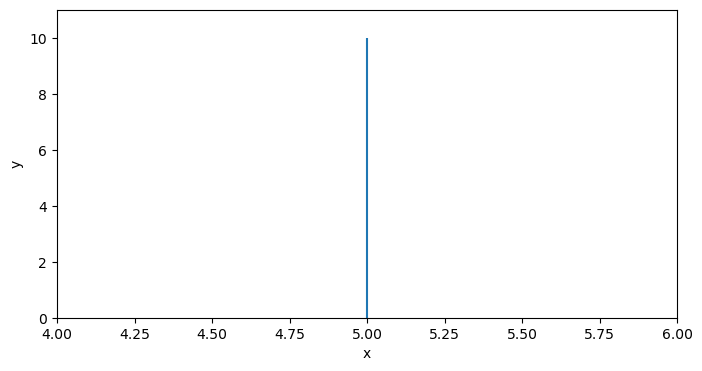

In [12]:
fig, ax = plt.subplots()
_ = ax.vlines(x=5, ymin=0, ymax=10)
_ = ax.set(xlim=(4, 6), ylim=(0, 11), xlabel="x", ylabel="y")
plt.show()

Define una función con `def`. La sangría delimita su contenido y `return` devuelve el resultado.

In [13]:
def cuadrado(x):
    return x ** 2

In [14]:
cuadrado(3)

9

Mueve el control para probar la misma función con distintos valores de `x`.

In [15]:
_ = widgets.interact(
    cuadrado,
    x=widgets.IntSlider(value=3, min=-10, max=10, description="x"),
)

interactive(children=(IntSlider(value=3, description='x', max=10, min=-10), Output()), _dom_classes=('widget-i…

### Ejercicio 1.1 — Productos vendidos por día

Una tienda ha vendido los siguientes productos durante tres días:

- Lunes: 15 productos.
- Martes: 22 productos.
- Miércoles: 18 productos.

Cada producto tiene un precio de venta de **12 €** y un coste de **7 €**.

Realiza las siguientes operaciones en Python:

1. Crea las variables `lunes`, `martes` y `miercoles`, asignándoles las ventas de cada día.
2. Crea las variables `precio` y `coste` con los valores correspondientes.
3. Calcula el número total de productos vendidos durante los tres días.
4. Calcula la media diaria de productos vendidos.
5. Calcula los ingresos totales de los tres días.
6. Calcula el beneficio total, considerando la diferencia entre ingresos y costes.
7. Crea una función llamada `beneficio` que calcule el beneficio a partir de las unidades vendidas en un día.
8. Aplica la función a las ventas del lunes y del martes.

In [16]:
# Tu solución

## Tipos de objetos

### Vectores

Un vector es una secuencia ordenada de valores del mismo tipo. Lo representamos mediante un array de NumPy.

In [17]:
v1 = np.array([32, 40, 61, 71, 39], dtype=float)  # Edades: valores numéricos
v1

array([32., 40., 61., 71., 39.])

In [18]:
v2 = np.arange(1, 6)  # Enteros del 1 al 5; el extremo final se excluye
v2

array([1, 2, 3, 4, 5])

In [19]:
v3 = np.array(["h", "m", "h", "m", "m"])  # Valores de texto
v3

array(['h', 'm', 'h', 'm', 'm'], dtype='<U1')

`type()` indica la clase del objeto; `dtype` indica el tipo de los elementos de un array.

In [20]:
type(v1)
v1.dtype
v2.dtype
v3.dtype

numpy.ndarray

dtype('float64')

dtype('int64')

dtype('<U1')

#### Acceso y modificación

**Los índices empiezan en 0.** El tercer elemento ocupa la posición 2.
En un intervalo `inicio:fin`, el extremo final se excluye.

In [21]:
v1[2]  # Tercer elemento

61.0

In [22]:
v1[2] = 62
v1[2]

62.0

In [23]:
v1[1:4]       # Elementos del segundo al cuarto
v1[[0, 1, 3]]  # Elementos primero, segundo y cuarto

array([40., 62., 71.])

array([32., 40., 71.])

### Matrices

Una matriz es un array de dos dimensiones, con filas y columnas del mismo tipo.

In [24]:
m1 = np.array([[10, 20], [30, 40]])
m1

array([[10, 20],
       [30, 40]])

In [25]:
m2 = np.column_stack((v1, v2))  # Para apilar filas: np.vstack((v1, v2))
m2

array([[32.,  1.],
       [40.,  2.],
       [62.,  3.],
       [71.,  4.],
       [39.,  5.]])

#### Acceso y modificación

In [26]:
m1[1, 0]  # Segunda fila, primera columna
m1[1, :]  # Segunda fila
m1[:, 0]  # Primera columna

30

array([30, 40])

array([10, 30])

In [27]:
m1[1, 0] = 35
m1

array([[10, 20],
       [35, 40]])

Para asignar nombres a las filas y columnas, representamos `m2` mediante una tabla de pandas.

In [28]:
m2 = pd.DataFrame(m2)
m2.columns = ["edad", "orden"]
m2.index = letters[:5]

m2.columns
m2.index
m2

Index(['edad', 'orden'], dtype='object')

Index(['a', 'b', 'c', 'd', 'e'], dtype='object')

,edad,orden
a,32.0,1.0
b,40.0,2.0
c,62.0,3.0
d,71.0,4.0
e,39.0,5.0


### DataFrames

Un DataFrame es una tabla con columnas de igual longitud. Cada columna puede contener un tipo diferente.
Al ejecutar una celda con el nombre de la tabla, aparece una vista tabular.
También puedes abrirla desde **Variables** en el visor de datos de VS Code.

In [29]:
df1 = pd.DataFrame({"x": letters[:10], "y": np.arange(1, 11)})
df1

,x,y
0,a,1
1,b,2
2,c,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


In [30]:
df2 = pd.DataFrame({"v3": v3, "v1": v1})
df2

,v3,v1
0,h,32.0
1,m,40.0
2,h,62.0
3,m,71.0
4,m,39.0


#### Acceso y modificación

Usa `iloc` para seleccionar por posición y `loc` para seleccionar por etiquetas o condiciones.

In [31]:
df1["x"]       # Columna llamada x
df1.x          # Acceso por atributo, cuando el nombre de la columna lo permite
df1.iloc[:, 0]  # Primera columna por posición

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: object

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: object

0    a
1    b
2    c
3    d
4    e
5    f
6    g
7    h
8    i
9    j
Name: x, dtype: object

In [32]:
df1.iloc[1, 0]       # Segunda fila, primera columna
df1["x"].iloc[1]    # El mismo elemento, seleccionando primero la columna

'b'

'b'

In [33]:
df1.iloc[1, :]  # Segunda fila

x    b
y    2
Name: 1, dtype: object

In [34]:
df1.iloc[1, 1] = 35
df1

,x,y
0,a,1
1,b,35
2,c,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


In [35]:
df1.iloc[2, 0] = "H"
df1

,x,y
0,a,1
1,b,35
2,H,3
3,d,4
4,e,5
5,f,6
6,g,7
7,h,8
8,i,9
9,j,10


#### Funciones de búsqueda útiles

In [36]:
np.flatnonzero(df1["x"] == "e")  # Posiciones que cumplen la condición

array([4])

In [37]:
df1["y"].idxmax()  # Etiqueta de la fila con el valor máximo
df1["y"].idxmin()  # Etiqueta de la fila con el valor mínimo

1

0

In [38]:
df1.loc[df1["x"] == "e"]
df1.loc[df1["y"] == df1["y"].max()]

,x,y
4,e,5


,x,y
1,b,35


### Listas

Una lista puede combinar vectores, matrices, tablas y otros objetos.

In [39]:
l1 = [v1, m1, df1]
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10]

Un intervalo devuelve una lista; un índice individual devuelve el objeto almacenado en esa posición.

In [40]:
l1[:1]
type(l1[:1])

[array([32., 40., 62., 71., 39.])]

list

In [41]:
l1[0]
type(l1[0])

array([32., 40., 62., 71., 39.])

numpy.ndarray

In [42]:
l1.append(np.arange(1, 11))  # Añadir un cuarto elemento
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10,
 array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])]

In [43]:
l1[3] = 4  # Sustituir el cuarto elemento
l1

[array([32., 40., 62., 71., 39.]),
 array([[10, 20],
        [35, 40]]),
    x   y
 0  a   1
 1  b  35
 2  H   3
 3  d   4
 4  e   5
 5  f   6
 6  g   7
 7  h   8
 8  i   9
 9  j  10,
 4]

### Ejercicio 1.2

1. Crea un DataFrame con los siguientes datos:

| marca | modelo | consumo |
| --- | --- | ---: |
| audi | A3 | 6.8 |
| volswagen | Polo | 6.8 |
| bmw | X5 | 12.5 |
| renault | megane | 4.7 |
| fiat | punto | 5.0 |

2. Modifica el consumo del fiat punto a **4.5**.

In [44]:
# Tu solución

## EXTRA: instrucciones útiles

### Programación

In [45]:
if v1[0] == 32:
    print("La edad del primer individuo es 32")

La edad del primer individuo es 32


In [46]:
for i in range(5):
    print(v1[i])

32.0
40.0
62.0
71.0
39.0


### Gestión de objetos

`%whos` lista los objetos de la sesión. El panel **Variables** ofrece una vista interactiva.

In [47]:
%whos

Variable     Type         Data/Info
-----------------------------------
LETTERS      ndarray      26: 26 elems, type `<U1`, 104 bytes
Path         type         <class 'pathlib.Path'>
ax           Axes         Axes(0.125,0.11;0.775x0.77)
calendar     module       <module 'calendar' from '<...>b/python3.8/calendar.py'>
csv          module       <module 'csv' from '/home<...>a3/lib/python3.8/csv.py'>
cuadrado     function     <function cuadrado at 0x766580f5df70>
df1          DataFrame       x   y\n0  a   1\n1  b <...>h   8\n8  i   9\n9  j  10
df2          DataFrame      v3    v1\n0  h  32.0\n1<...>0\n3  m  71.0\n4  m  39.0
display      function     <function display at 0x7665c5807790>
fig          Figure       Figure(800x400)
i            int          4
l1           list         n=4
letters      ndarray      26: 26 elems, type `<U1`, 104 bytes
m1           ndarray      2x2: 4 elems, type `int64`, 32 bytes
m2           DataFrame       edad  orden\na  32.0  <...>.0    4.0\ne  39.0    5.0
m

In [48]:
sys.getsizeof(v1)  # Memoria ocupada por el objeto, en bytes

152

In [49]:
del v1  # Eliminar una variable de la sesión

`%reset -f` vacía el espacio de variables, incluidas las importaciones.
Ejecuta la siguiente celda cuando hayas terminado con los ejemplos anteriores.
Después, la celda de importaciones prepara la sesión para trabajar con los archivos.

In [50]:
%reset -f

In [51]:
import calendar
import csv
import math
import string
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from statsmodels.graphics.mosaicplot import mosaic

## Lectura de datos

### Leer un fichero de texto

Buscamos la carpeta `datos` del proyecto desde la carpeta de trabajo actual.
Así puedes abrir el notebook desde la raíz del proyecto o desde `sesiones/sesion1`.

In [52]:
for carpeta in (Path.cwd(), *Path.cwd().parents):
    if (carpeta / "datos" / "Mobiles.txt").is_file():
        DATA_PATH = carpeta / "datos"
        break
else:
    raise FileNotFoundError("Abre el notebook dentro de la carpeta LaSalle_Estadistica.")

`Mobiles.txt` tiene cabecera, columnas separadas por punto y coma y punto decimal.
En esta primera lectura identificamos únicamente `NA` como valor ausente.
Las columnas de texto se representan como variables categóricas.

In [53]:
datos = pd.read_csv(
    DATA_PATH / "Mobiles.txt",
    sep=";", decimal=".", na_values=["NA"], keep_default_na=False,
)
for columna in datos.select_dtypes(include="object"):
    datos[columna] = datos[columna].astype("category")

### Inspección de los datos

In [54]:
datos.shape  # Número de filas y columnas

(179, 10)

In [55]:
datos.head()  # Primeras filas

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
0,Female,17,Arts,LG,Silver,Telstra,Plan,70.0,SMS,1
1,Male,21,Arts,Motorola,Silver,Overseas,Prepaid,200.0,Calls,3
2,Female,20,Arts,Samsung,Silver,Optus,Prepaid,30.0,Both,1
3,Male,23,Arts,,,,,NaN,,2
4,Female,38,Arts,Nokia,Blue,Optus,Plan,120.0,Calls,3


In [56]:
datos.describe(include="all")  # Descriptiva de todas las columnas

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,179,179,179,179,174.000000,179,179.000000
unique,2,NaN,10,15,13,7,3,NaN,4,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


### Reconocer los valores ausentes

También hay campos vacíos que representan datos ausentes. Repetimos la lectura incluyendo `""`.
`keep_default_na=False` permite decidir explícitamente qué valores se consideran ausentes.

In [57]:
datos = pd.read_csv(
    DATA_PATH / "Mobiles.txt",
    sep=";", decimal=".", na_values=["NA", ""], keep_default_na=False,
)
for columna in datos.select_dtypes(include="object"):
    datos[columna] = datos[columna].astype("category")

In [58]:
datos.describe(include="all")
datos.isna().sum()  # Valores ausentes por columna

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,174,174,174,174,174.000000,174,179.000000
unique,2,NaN,10,14,12,6,2,NaN,3,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


Gender        0
Age           0
Faculty       0
Brand         5
Colour        5
Provider      5
PlanType      5
Bill          5
PrimaryUse    5
No.Phones     0
dtype: int64

### Explorar la tabla

Elige una marca y cuántas filas quieres ver. El filtro solo cambia la vista; `datos` conserva todas sus filas.

In [59]:
def explorar_moviles(marca, filas):
    vista = datos if marca == "Todas" else datos.loc[datos["Brand"] == marca]
    print(f"{len(vista)} observaciones; mostrando hasta {filas} filas.")
    display(vista.head(filas))

In [60]:
visor_moviles = widgets.interactive(
    explorar_moviles,
    marca=widgets.Dropdown(options=["Todas", *datos["Brand"].cat.categories], description="Marca"),
    filas=widgets.IntSlider(value=10, min=1, max=50, description="Filas", continuous_update=False),
)
display(visor_moviles)

interactive(children=(Dropdown(description='Marca', options=('Todas', 'Alcatel', 'Ericsson', 'LG', 'Motorola',…

### Ejercicio 1.3

1. Lee `flights.txt`, ajusta los parámetros de lectura y guarda la tabla en `datos2`.
   Presta atención al separador y al símbolo utilizado para los valores ausentes.
2. Inspecciona los datos: número de filas y columnas, visualización de la tabla y descriptiva global.
3. ¿Cuánto tiempo estuvo en el aire el vuelo **251** con número de cola **N855UA**?

El fichero está en `DATA_PATH / "flights.txt"`.

In [61]:
# Tu solución

## Escritura de datos a un fichero

### Guardar una tabla de texto

Guardamos los resultados en `sesiones/sesion1/salidas`.
Separamos las columnas con tabuladores, omitimos el índice y escribimos las categorías sin comillas.
Los valores ausentes se representan con `NA`.

In [62]:
OUTPUT_PATH = DATA_PATH.parent / "sesiones" / "sesion1" / "salidas"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

datos.to_csv(
    OUTPUT_PATH / "Mobiles_test.txt",
    sep="\t", index=False, quoting=csv.QUOTE_NONE, na_rep="NA",
)

Guarda el subconjunto de móviles Nokia en `Nokia_test.txt`.

In [63]:
datos.loc[datos["Brand"] == "Nokia"].to_csv(
    OUTPUT_PATH / "Nokia_test.txt",
    sep="\t", index=False, quoting=csv.QUOTE_NONE, na_rep="NA",
)

### Ejercicio 1.4

Guarda los vuelos que estuvieron en el aire menos de una hora en un fichero llamado `short_flights_test.txt`.

El fichero debe tener las columnas separadas por tabuladores, sin comillas para las categorías,
sin nombres de columnas y sin índice de filas. Usa la carpeta `OUTPUT_PATH` para guardar tu resultado.

In [64]:
# Tu solución

## Descriptiva univariante

Volvemos a leer la tabla de móviles con los valores ausentes correctamente identificados.

In [65]:
datos = pd.read_csv(
    DATA_PATH / "Mobiles.txt",
    sep=";", decimal=".", na_values=["NA", ""], keep_default_na=False,
)
for columna in datos.select_dtypes(include="object"):
    datos[columna] = datos[columna].astype("category")

In [66]:
datos.shape
datos.columns
datos.describe(include="all")

(179, 10)

Index(['Gender', 'Age', 'Faculty', 'Brand', 'Colour', 'Provider', 'PlanType',
       'Bill', 'PrimaryUse', 'No.Phones'],
      dtype='object')

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
count,179,179.000000,179,174,174,174,174,174.000000,174,179.000000
unique,2,NaN,10,14,12,6,2,NaN,3,NaN
top,Male,NaN,Business,Nokia,Silver,Optus,Prepaid,NaN,Both,NaN
freq,96,NaN,68,104,49,98,98,NaN,68,NaN
mean,NaN,22.217877,NaN,NaN,NaN,NaN,NaN,46.850575,NaN,2.385475
std,NaN,6.366389,NaN,NaN,NaN,NaN,NaN,41.577570,NaN,1.848781
min,NaN,17.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,1.000000
50%,NaN,20.000000,NaN,NaN,NaN,NaN,NaN,35.000000,NaN,2.000000
75%,NaN,24.000000,NaN,NaN,NaN,NaN,NaN,60.000000,NaN,3.000000


### Variable numérica

#### Estadísticos principales

In [67]:
datos["Age"].mean()

22.217877094972067

In [68]:
datos["Age"].var(ddof=1)  # Varianza muestral

40.530914569079194

Con `skipna=False`, la desviación resulta ausente si hay datos ausentes. Con `skipna=True` los excluimos.

In [69]:
datos["Bill"].std(skipna=False, ddof=1)
datos["Bill"].std(skipna=True, ddof=1)

nan

41.57756974651329

In [70]:
datos["Bill"].describe()

count    174.000000
mean      46.850575
std       41.577570
min        0.000000
25%       25.000000
50%       35.000000
75%       60.000000
max      300.000000
Name: Bill, dtype: float64

#### ¿Qué representan los cuartiles?

En la factura, el primer cuartil es 25, la mediana es 35 y el tercer cuartil es 60.
Calculamos la proporción de observaciones que no supera cada valor, usando como denominador
el número total de observaciones de la tabla.

In [71]:
n = datos.shape[0]

(datos["Bill"] <= 25.00).sum() / n
(datos["Bill"] <= 35.00).sum() / n
(datos["Bill"] <= 60.00).sum() / n

0.2681564245810056

0.4972067039106145

0.8044692737430168

#### Rango intercuartílico: distancia entre el tercer cuartil y el primero

In [72]:
iqr = datos["Bill"].quantile(0.75) - datos["Bill"].quantile(0.25)
iqr

35.0

#### Diagrama de caja

Activa o desactiva las líneas de referencia para identificar los cuartiles y los límites.
El límite de valores atípicos es una referencia; el bigote alcanza la observación más extrema dentro del límite.

In [73]:
def caja_factura(referencias):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(datos["Bill"].dropna(), vert=False, patch_artist=True,
               boxprops={"facecolor": "blue", "alpha": 0.5})
    if referencias:
        lineas = [
            (25, "black", "Primer cuartil: 25"),
            (35, "red", "Mediana: 35"),
            (60, "green", "Tercer cuartil: 60"),
            (0, "blue", "Bigote inferior: 0"),
            (60 + 1.5 * iqr, "purple", "Límite superior de atípicos"),
        ]
        for valor, color, etiqueta in lineas:
            ax.axvline(valor, linestyle="--", color=color, label=etiqueta)
        ax.legend(loc="upper right", fontsize=8)
    ax.set(title="Factura", xlabel="Factura", yticks=[])
    fig.tight_layout()
    plt.show()

In [74]:
control_caja = widgets.interactive(
    caja_factura,
    referencias=widgets.Checkbox(value=True, description="Mostrar líneas"),
)
display(control_caja)

interactive(children=(Checkbox(value=True, description='Mostrar líneas'), Output()), _dom_classes=('widget-int…

#### Histograma de la edad

La altura representa densidad. Cambia el número de intervalos y selecciona un tramo de edades.
La franja sombreada sirve de referencia para calcular su proporción y su densidad media.

In [75]:
def histograma_edad(intervalos, tramo):
    edades = datos["Age"].dropna()
    inferior, superior = tramo
    fig, ax = plt.subplots()
    ax.hist(edades, bins=intervalos, density=True, color="navy", edgecolor="white")
    ax.axvspan(inferior, superior, color="orange", alpha=0.3)
    ax.set(title="Distribución de la edad", xlabel="Edad", ylabel="Densidad")
    fig.tight_layout()
    plt.show()
    if superior > inferior:
        proporcion = ((datos["Age"] > inferior) & (datos["Age"] < superior)).sum() / len(datos)
        print(f"Proporción en el intervalo abierto: {proporcion:.4f}")
        print(f"Densidad media en el intervalo: {proporcion / (superior - inferior):.4f}")
    else:
        print("Separa los extremos del tramo para calcular la densidad.")

In [76]:
control_histograma = widgets.interactive(
    histograma_edad,
    intervalos=widgets.IntSlider(value=10, min=4, max=30, description="Intervalos", continuous_update=False),
    tramo=widgets.IntRangeSlider(value=(20, 25), min=int(datos["Age"].min()),
                                max=int(datos["Age"].max()), description="Edades", continuous_update=False),
)
display(control_histograma)

interactive(children=(IntSlider(value=10, continuous_update=False, description='Intervalos', max=30, min=4), I…

Densidad media entre 20 y 25 años: proporción en el intervalo abierto dividida por su amplitud, 5.

In [77]:
((datos["Age"] > 20) & (datos["Age"] < 25)).sum() / datos.shape[0] / 5

0.055865921787709494

### Variable categórica

#### Tablas de frecuencias, proporciones y porcentajes

Las tablas excluyen los valores ausentes. Conservamos los nombres de las categorías tal como aparecen en el fichero.

In [78]:
frecuencias = datos["Brand"].value_counts(sort=False).sort_index()
frecuencias

Brand
Alcatel        1
Ericsson       9
LG             3
Motorola      16
NEC            6
Nokia        104
Panasonic      6
Phillips       1
Samsung        8
Sharp          1
Siemens       10
Sony           7
mno            1
samsung        1
Name: count, dtype: int64

In [79]:
proporciones = datos["Brand"].value_counts(normalize=True, sort=False).sort_index()
proporciones

Brand
Alcatel      0.005747
Ericsson     0.051724
LG           0.017241
Motorola     0.091954
NEC          0.034483
Nokia        0.597701
Panasonic    0.034483
Phillips     0.005747
Samsung      0.045977
Sharp        0.005747
Siemens      0.057471
Sony         0.040230
mno          0.005747
samsung      0.005747
Name: proportion, dtype: float64

In [80]:
(100 * proporciones).round(1)

Brand
Alcatel       0.6
Ericsson      5.2
LG            1.7
Motorola      9.2
NEC           3.4
Nokia        59.8
Panasonic     3.4
Phillips      0.6
Samsung       4.6
Sharp         0.6
Siemens       5.7
Sony          4.0
mno           0.6
samsung       0.6
Name: proportion, dtype: float64

#### Diagrama de barras

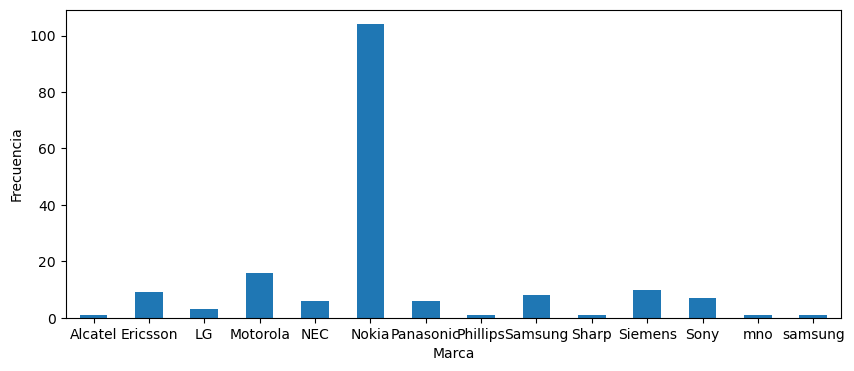

In [81]:
ax = frecuencias.plot.bar(rot=0, figsize=(10, 4))
_ = ax.set(xlabel="Marca", ylabel="Frecuencia")
plt.show()

#### Diagrama de barras ordenado

Gira las etiquetas para facilitar su lectura. El control permite cambiar el orden de las barras.

In [82]:
def barras_marcas(ordenar):
    tabla_marcas = datos["Brand"].value_counts(sort=False).sort_index()
    if ordenar:
        tabla_marcas = tabla_marcas.sort_values()
    ax = tabla_marcas.plot.bar(rot=90, figsize=(10, 4))
    ax.set(title="Marcas de móviles", xlabel="Marca", ylabel="Frecuencia")
    ax.figure.tight_layout()
    plt.show()

In [83]:
control_marcas = widgets.interactive(
    barras_marcas,
    ordenar=widgets.Checkbox(value=True, description="Ordenar por frecuencia"),
)
display(control_marcas)

interactive(children=(Checkbox(value=True, description='Ordenar por frecuencia'), Output()), _dom_classes=('wi…

### Ejercicio 1.5

1. Realiza la descriptiva de la variable tiempo de vuelo (`air_time`) de `flights.txt`.
2. Realiza la descriptiva de la variable categórica origen (`origin`) del mismo conjunto de datos.

In [84]:
# Tu solución

## Descriptiva bivariante

### Numérica y numérica

#### Correlación

La correlación mide la relación lineal entre dos variables y toma valores entre −1 y 1.
Se calcula con las observaciones que tienen ambos valores disponibles.

In [85]:
datos["Age"].corr(datos["Bill"])

0.2900709854542837

In [86]:
datos[["Age", "Bill"]].corr().loc["Age", "Bill"]  # Mediante la matriz de correlaciones

0.2900709854542837

#### Diagrama de dispersión

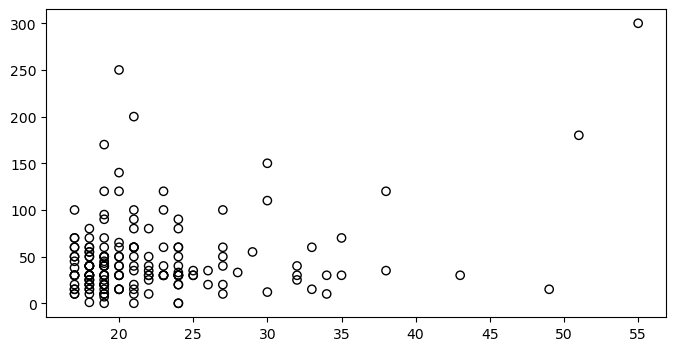

In [87]:
fig, ax = plt.subplots()
_ = ax.scatter(datos["Age"], datos["Bill"], facecolors="none", edgecolors="black")
plt.show()

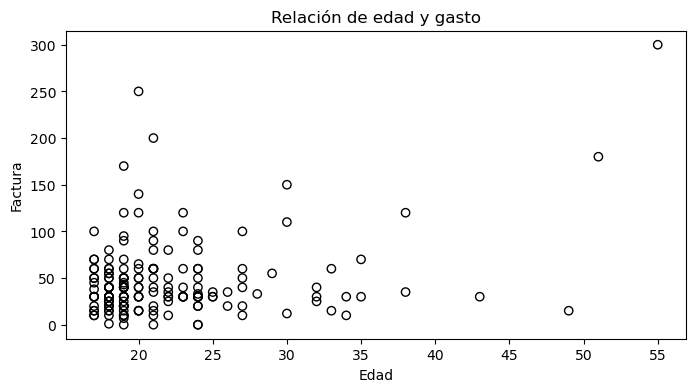

In [88]:
fig, ax = plt.subplots()
_ = ax.scatter(datos["Age"], datos["Bill"], facecolors="none", edgecolors="black")
_ = ax.set(xlabel="Edad", ylabel="Factura", title="Relación de edad y gasto")
plt.show()

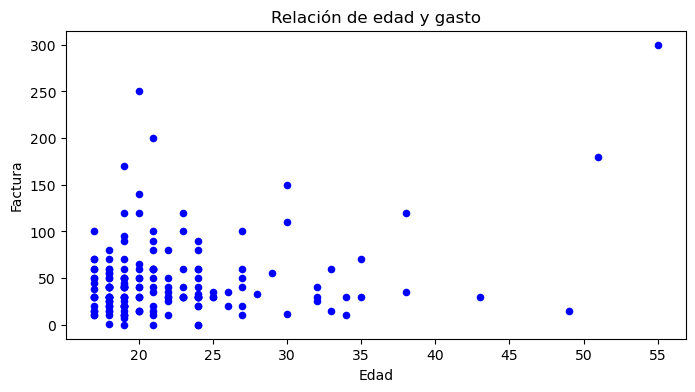

In [89]:
ax = datos.plot.scatter(x="Age", y="Bill", color="blue", s=20)
_ = ax.set(xlabel="Edad", ylabel="Factura", title="Relación de edad y gasto")
plt.show()

#### Logaritmos y separación de puntos superpuestos

Transformamos la edad con `log(Edad)` y la factura con `log(Factura + 0.1)` para admitir facturas de valor cero.
Añadimos una pequeña perturbación aleatoria (*jitter*) para separar los puntos superpuestos.

Prueba la transformación y ajusta la dispersión. Con dispersión cero se muestran las posiciones sin perturbación.
La semilla fija permite repetir el gráfico con el mismo desplazamiento.

In [90]:
def dispersion_edad_factura(logaritmos, dispersion):
    pares = datos[["Age", "Bill"]].dropna()
    x = pares["Age"].to_numpy(dtype=float)
    y = pares["Bill"].to_numpy(dtype=float)
    if logaritmos:
        x = np.log(x)
        y = np.log(y + 0.1)
    rng = np.random.default_rng(42)
    x = x + rng.uniform(-dispersion, dispersion, size=len(x))
    y = y + rng.uniform(-dispersion, dispersion, size=len(y))
    fig, ax = plt.subplots()
    ax.scatter(x, y, color="blue", s=20)
    ax.set(xlabel="log(Edad)" if logaritmos else "Edad",
           ylabel="log(Factura + 0.1)" if logaritmos else "Factura",
           title="Relación de edad y gasto")
    fig.tight_layout()
    plt.show()

In [91]:
control_dispersion = widgets.interactive(
    dispersion_edad_factura,
    logaritmos=widgets.Checkbox(value=True, description="Aplicar logaritmos"),
    dispersion=widgets.FloatSlider(value=0.02, min=0, max=0.2, step=0.01,
                                   description="Dispersión", continuous_update=False),
)
display(control_dispersion)

interactive(children=(Checkbox(value=True, description='Aplicar logaritmos'), FloatSlider(value=0.02, continuo…

### Numérica y categórica

La descriptiva estratificada y el diagrama de caja por grupos se desarrollan al final de este apartado.

### Categórica y categórica

#### Tablas cruzadas

Relacionamos el tipo de contrato (`PlanType`) con el uso principal (`PrimaryUse`).

In [92]:
pd.crosstab(datos["PlanType"], datos["PrimaryUse"])  # Frecuencias

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,33,22,21
Prepaid,35,16,47


In [93]:
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="all")  # Proporciones globales

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.189655,0.126437,0.120690
Prepaid,0.201149,0.091954,0.270115


In [94]:
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="index")  # Proporciones por filas

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.434211,0.289474,0.276316
Prepaid,0.357143,0.163265,0.479592


In [95]:
pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize="columns")  # Proporciones por columnas

PrimaryUse,Both,Calls,SMS
PlanType,,,
Plan,0.485294,0.578947,0.308824
Prepaid,0.514706,0.421053,0.691176


Elige la normalización para explorar sobre qué total se calcula cada proporción.

In [96]:
def tabla_contrato_uso(normalizacion):
    display(pd.crosstab(datos["PlanType"], datos["PrimaryUse"], normalize=normalizacion))

In [97]:
control_tabla = widgets.interactive(
    tabla_contrato_uso,
    normalizacion=widgets.Dropdown(
        options=[("Frecuencias", False), ("Proporciones globales", "all"),
                 ("Proporciones por filas", "index"), ("Proporciones por columnas", "columns")],
        description="Tabla", layout=widgets.Layout(width="360px"),
    ),
)
display(control_tabla)

interactive(children=(Dropdown(description='Tabla', layout=Layout(width='360px'), options=(('Frecuencias', Fal…

#### Diagramas de barras apiladas y agrupadas

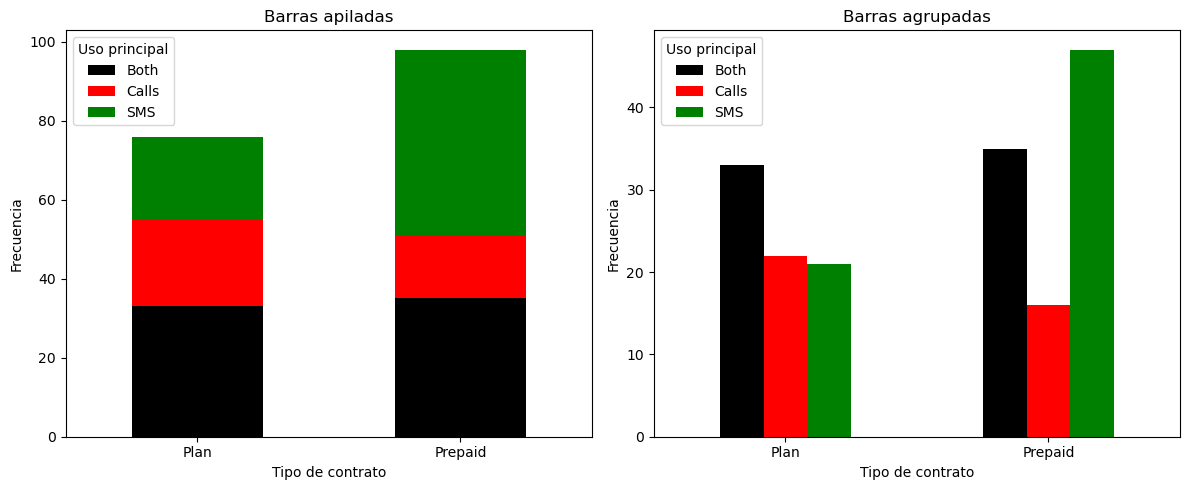

In [98]:
tabla_uso_plan = pd.crosstab(datos["PrimaryUse"], datos["PlanType"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

_ = tabla_uso_plan.T.plot.bar(stacked=True, ax=axes[0], color=["black", "red", "green"], rot=0)
_ = tabla_uso_plan.T.plot.bar(stacked=False, ax=axes[1], color=["black", "red", "green"], rot=0)
_ = axes[0].set(title="Barras apiladas", xlabel="Tipo de contrato", ylabel="Frecuencia")
_ = axes[1].set(title="Barras agrupadas", xlabel="Tipo de contrato", ylabel="Frecuencia")
for ax in axes:
    _ = ax.legend(title="Uso principal", loc="upper left")
fig.tight_layout()
plt.show()

#### Diagrama de mosaico

El área de cada rectángulo representa su frecuencia. Los colores identifican el tipo de contrato.

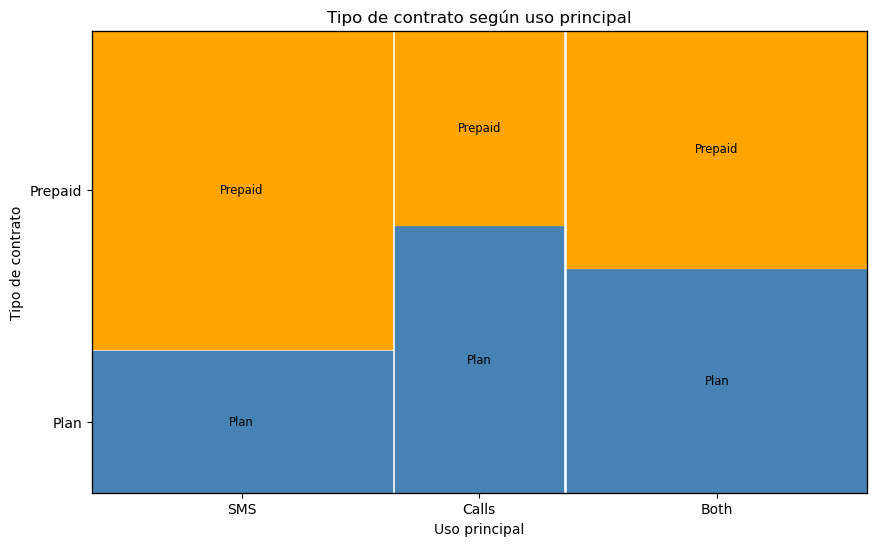

In [99]:
colores_plan = {"Plan": "steelblue", "Prepaid": "orange"}
fig, ax = plt.subplots(figsize=(10, 6))
_ = mosaic(
    datos.dropna(subset=["PrimaryUse", "PlanType"]),
    ["PrimaryUse", "PlanType"], ax=ax,
    properties=lambda clave: {"color": colores_plan[clave[1]]},
    labelizer=lambda clave: clave[1],
    title="Tipo de contrato según uso principal",
)
_ = ax.set(xlabel="Uso principal", ylabel="Tipo de contrato")
plt.show()

#### Descriptiva numérica estratificada

Describimos la factura globalmente y después por tipo de contrato.

In [100]:
datos["Bill"].describe()

count    174.000000
mean      46.850575
std       41.577570
min        0.000000
25%       25.000000
50%       35.000000
75%       60.000000
max      300.000000
Name: Bill, dtype: float64

In [101]:
datos.groupby("PlanType", observed=True)["Bill"].describe()

,count,mean,std,min,25%,50%,75%,max
PlanType,,,,,,,,
Plan,76.0,61.171053,51.058499,0.0,32.25,40.0,70.0,300.0
Prepaid,98.0,35.744898,27.966958,0.0,20.00,30.0,50.0,200.0


In [102]:
datos.groupby("PlanType", observed=True)["Bill"].std(ddof=1)

PlanType
Plan       51.058499
Prepaid    27.966958
Name: Bill, dtype: float64

#### Diagrama de caja estratificado

Cada caja representa las facturas de un tipo de contrato. Activa los puntos para ver las observaciones individuales.

In [103]:
def cajas_por_plan(puntos):
    planes = list(datos["PlanType"].cat.categories)
    grupos = [datos.loc[datos["PlanType"] == plan, "Bill"].dropna() for plan in planes]
    posiciones = np.arange(len(planes))
    fig, ax = plt.subplots()
    ax.boxplot(grupos, positions=posiciones, patch_artist=True,
               boxprops={"facecolor": "steelblue", "alpha": 0.6})
    ax.set_xticks(posiciones)
    ax.set_xticklabels(planes)
    if puntos:
        rng = np.random.default_rng(42)
        for posicion, grupo in zip(posiciones, grupos):
            ax.scatter(posicion + rng.uniform(-0.1, 0.1, len(grupo)), grupo,
                       color="black", s=12, alpha=0.4)
    ax.set(title="Factura según plan", xlabel="Tipo de contrato", ylabel="Factura")
    fig.tight_layout()
    plt.show()

In [104]:
control_planes = widgets.interactive(
    cajas_por_plan,
    puntos=widgets.Checkbox(value=False, description="Mostrar observaciones"),
)
display(control_planes)

interactive(children=(Checkbox(value=False, description='Mostrar observaciones'), Output()), _dom_classes=('wi…

### Ejercicio 1.6

1. Realiza la descriptiva del retraso en la llegada (`arr_delay`) según el retraso en la salida (`dep_delay`).
   Calcula la correlación y dibuja el diagrama de dispersión. Usa también `plt.hexbin()` para representar la densidad de puntos.

In [105]:
# Apartado 1

2. Realiza la descriptiva del retraso en la llegada según el mes del año (`month`).
   Obtén el resumen del retraso por mes y el diagrama de caja estratificado.

   Crea un subconjunto de `datos2` llamado `datos2_delay` con los vuelos que llegaron con retraso.
   Repite la descriptiva anterior con ese subconjunto.

In [106]:
# Apartado 2

3. Realiza la descriptiva de la hora de llegada (`arr_time`) según la hora de salida (`hour`),
   tratando esta última como una variable categórica.

   Crea una nueva columna dentro de `datos2` que categorice `hour` en tres grupos: **[0–8]**, **[9–16]** y **[17–24]**.
   Repite la descriptiva anterior. Consulta la ayuda de `pd.cut`.

In [107]:
# Apartado 3